# Knowledge Conflict 복습과제 — 내부 지식과 외부 문맥의 선택 조절

**논문:** Lou et al., *Which Knowledge Should LLMs Trust? Uncovering a Generalizable Steering Direction Across Knowledge Conflicts*, arXiv:2610.20067v1 (2026)

질문만 있는 입력과 충돌 문맥이 있는 입력을 구성하고, 층별 표현의 코사인 유사도로 개입 층을 선택합니다. 이어서 평균 차이 벡터와 $h'=h+\alpha v$를 구현하고, 출처 선택 지표와 논문 결과를 해석합니다.

| Part | 내용 | 논문 연결 |
|---|---|---|
| 1 | 프롬프트 쌍과 방향 추정용 예시 선별 | §3.3 |
| 2 | 마지막 토큰 표현, 개입 층, 방향 벡터 | §3.3, 식 (2)–(4) |
| 3 | 활성화 수정과 α 선택 | §3.4, 식 (5), §4 |
| 4 | 출처 매칭 지표와 보고된 실험 수치 | §3.5, 표 1·6·7, 부록 C |
| 5 | 서술형 복습과 토론 | §4.4–5, Limitations |

**진행 방법**
- Colab의 **파일 → 노트북 업로드**로 열고 위에서부터 실행하세요. CPU로 충분하며 모델·데이터 다운로드나 API 키가 필요 없습니다.
- `________`를 TODO ①–⑬의 설명에 맞게 채우세요. 코드 다음의 **✅ 확인 셀**로 점검하세요.
- 예상 소요 시간: 약 40–60분. 코드 실행과 서술형 답을 포함한 `.ipynb`를 제출하세요.
- NumPy와 Matplotlib을 사용합니다. Colab 기본 환경에 포함되어 있습니다.

**실습 범위**
Part 2–3의 활성화는 계산 원리를 학습하도록 **직접 구성한 합성 배열**입니다. 실제 Transformer에서 추출한 활성화가 아니며, 출력도 고정된 선형 분류기로 계산합니다. 합성 데이터의 결과로 실제 LLM의 성능·최적 층·일반화를 입증할 수 없습니다. Part 4의 수치는 별도로 표시한 **논문 보고값**입니다.



In [1]:
# 0. 환경 설정 — 이 노트북에서는 가중치를 학습하지 않습니다.
import re
import string
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(42)
print('NumPy:', np.__version__)


NumPy: 2.5.4


---
## Part 1. 프롬프트 쌍 구성하기

파라미터 지식은 모델 가중치에 저장된 지식이고, 문맥 지식은 현재 입력에서 제공된 정보입니다.

### 문제 1-1. Clean / Conflict prompt
- Clean: 질문만 제공합니다.
- Conflict: 기존 지식과 충돌하는 문맥을 질문 앞에 붙입니다.
- 두 입력의 질문은 동일하게 유지합니다. 프롬프트 구성만으로 내부 활성화를 직접 수정하는 것은 아닙니다.


In [2]:
def build_prompt(question, context=None):
    prefix = '' if context is None else context.strip() + '\n'
    return prefix + f'Question: {question}\nAnswer:'

query = 'What is the capital of France?'
wrong_context = 'The capital of France is Lyon.'
clean_prompt = build_prompt(query)  # 풀이 ①: 질문만 있는 프롬프트
conflict_prompt = build_prompt(query, wrong_context)  # 풀이 ②: 충돌 문맥과 같은 질문
print('[Clean]\n' + clean_prompt)
print('\n[Conflict]\n' + conflict_prompt)


[Clean]
Question: What is the capital of France?
Answer:

[Conflict]
The capital of France is Lyon.
Question: What is the capital of France?
Answer:


In [3]:
# ✅ 확인 셀
assert clean_prompt == 'Question: What is the capital of France?\nAnswer:'
assert conflict_prompt.startswith(wrong_context + '\n')
assert conflict_prompt.endswith(clean_prompt)
assert 'Lyon' not in clean_prompt
print('✅ 질문을 유지하면서 충돌 문맥만 추가했습니다.')


✅ 질문을 유지하면서 충돌 문맥만 추가했습니다.


### 문제 1-2. 방향 추정에 사용할 예시 고르기

논문 §3.3에서는 원래 질문과 패러프레이즈 네 개에 정확히 답하고, 충돌 문맥에서는 삽입된 대안 답을 따르는 예시를 남깁니다.

아래 기록은 **실제 모델을 실행한 기록이 아닌 설명용 예시**입니다. 정답 여부가 미리 주어졌다고 가정합니다. 이 선별 규칙은 방향 추정용 예시의 규칙이며, 모든 평가 항목에 같은 조건을 요구한다는 뜻은 아닙니다.


In [4]:
records = [
    {'id': 'A', 'clean_correct': [True]*5, 'conflict_uses_context': True},
    {'id': 'B', 'clean_correct': [True, True, False, True, True], 'conflict_uses_context': True},
    {'id': 'C', 'clean_correct': [True]*5, 'conflict_uses_context': False},
    {'id': 'D', 'clean_correct': [True]*5, 'conflict_uses_context': True},
]

def eligible(record):
    return all(record['clean_correct']) and record['conflict_uses_context']  # 풀이 ③: clean 계열 5개가 모두 정답이고 conflict에서 문맥 답 선택

selected_ids = [r['id'] for r in records if eligible(r)]
print('선별된 예시:', selected_ids)


선별된 예시: ['A', 'D']


In [5]:
# ✅ 확인 셀
assert selected_ids == ['A', 'D']
assert eligible({'clean_correct': [False]*5, 'conflict_uses_context': True}) is False
assert eligible({'clean_correct': [True]*5, 'conflict_uses_context': False}) is False
print('✅ 안정적인 기존 지식과 문맥 답 선택이라는 두 조건을 적용했습니다.')


✅ 안정적인 기존 지식과 문맥 답 선택이라는 두 조건을 적용했습니다.


### 문제 1-3 (서술형)
Fine-tuning, 프롬프트 변경, 이 논문의 활성화 스티어링에서 각각 무엇이 바뀌나요? 모델 가중치, 입력, 은닉 표현을 구분해 설명하세요.


**답:** 
- Fine-tuning: 과제 손실의 역전파와 최적화로 모델 가중치를 갱신한다.
- 프롬프트 변경: 모델 입력을 바꾸며, 이에 따라 은닉 표현과 출력도 달라질 수 있다. 입력 변경 자체는 가중치 갱신이 아니다.
- 활성화 스티어링: 가중치를 고정하고 추론 중 특정 층·토큰의 잔차 표현을 직접 h′ = h + αv로 수정한다. 프롬프트 쌍은 v를 추정하는 데 사용한다.


---
## Part 2. 개입 층과 방향 벡터 계산하기

### 문제 2-1. 각 입력의 마지막 유효 토큰 찾기

활성화 배열의 크기는 `[층 수 L, 예시 수 B, 최대 토큰 수 T, 은닉 차원 D]`입니다. `attention_mask`는 실제 토큰에서 1, 패딩에서 0입니다.

Clean과 Conflict는 길이가 다르므로 **각 입력의 마지막 실제 토큰** 표현을 추출해야 합니다. 패딩 위치를 추출하면 안 됩니다. 아래 자료에는 왼쪽·오른쪽 패딩이 모두 있습니다.

`mask.sum(axis=1)-1`은 오른쪽 패딩에서는 가능하지만 왼쪽 패딩에 일반화되지 않습니다. 각 행에서 1이 나타나는 가장 큰 위치를 찾으세요.


In [6]:
# 합성 활성화 준비 코드입니다. 이 셀은 수정하지 않습니다.
L, B, T, D = 4, 8, 7, 4
clean_mask = np.array([[1,1,1,0,0,0,0], [0,0,0,0,1,1,1]] * 4)
conflict_mask = np.array([[1,1,1,1,1,0,0], [0,0,1,1,1,1,1]] * 4)

clean_states = np.full((L, B, T, D), -99.0)
conflict_states = np.full((L, B, T, D), -99.0)
clean_centers = np.array([[1,0,0,0]] * L, dtype=float)
conflict_centers = np.array([[1,.05,0,0], [1,.5,0,0], [.1,1,0,0], [-1,0,0,0]])
# 교대로 더하고 빼서 예시별 차이는 있지만 평균은 중심값과 같게 만듭니다.
offset = np.zeros((B,D))
offset[:,2] = np.tile([.03,-.03], B//2)
for layer in range(L):
    for b in range(B):
        clean_states[layer,b,clean_mask[b].astype(bool)] = clean_centers[layer] + offset[b]
        conflict_states[layer,b,conflict_mask[b].astype(bool)] = conflict_centers[layer] + offset[b]

def last_token_states(states, mask):
    assert states.ndim == 4 and states.shape[1:3] == mask.shape
    assert (mask.sum(axis=1) > 0).all(), '모든 입력에는 실제 토큰이 있어야 합니다.'
    positions = np.arange(mask.shape[1])[None, :]
    last = np.where(mask == 1, positions, -1).max(axis=1)  # 풀이 ④: 실제 토큰 위치 중 최댓값. 패딩 위치는 -1로 처리
    return states[:, np.arange(mask.shape[0]), last, :]  # [L,B,D]

clean_last = last_token_states(clean_states, clean_mask)
conflict_last = last_token_states(conflict_states, conflict_mask)
print('추출한 배열 크기:', clean_last.shape)


추출한 배열 크기: (4, 8, 4)


In [7]:
# ✅ 확인 셀
assert clean_last.shape == conflict_last.shape == (L, B, D)
np.testing.assert_allclose(clean_last[:,0], clean_states[:,0,2])
np.testing.assert_allclose(clean_last[:,1], clean_states[:,1,6])
np.testing.assert_allclose(conflict_last[:,0], conflict_states[:,0,4])
assert not np.any(clean_last == -99)
assert not np.any(conflict_last == -99)
print('✅ 패딩 방향과 입력 길이가 달라도 마지막 실제 토큰을 추출합니다.')


✅ 패딩 방향과 입력 길이가 달라도 마지막 실제 토큰을 추출합니다.


### 문제 2-2. 코사인 유사도로 개입 층 선택하기

각 층에서 **예시들의 평균 벡터를 먼저 계산한 뒤**, 두 평균 사이 코사인 유사도를 계산합니다.

$$s_l = \frac{\bar h_l^{clean}\cdot\bar h_l^{conflict}}{\|\bar h_l^{clean}\|\|\bar h_l^{conflict}\|}$$

유사도가 작을수록 각도 차이는 큽니다. 이 실습에서는 **마지막 층을 후보에서 제외**합니다. 논문도 마지막 층의 분리가 출력 분포 자체를 반영할 경우 개입 후보에서 제외합니다. 모든 Transformer에 마지막 층 제외 규칙이 보편적으로 성립한다는 뜻은 아닙니다.

이 노트북의 층 번호는 0부터 시작하며, 합성 자료의 선택 결과를 논문 모델의 실제 개입 층 번호와 동일시하지 마세요.


In [8]:
def layer_cosines(clean_last, conflict_last):
    clean_mean = clean_last.mean(axis=1)  # 풀이 ⑤: 예시 축(B)에 대한 평균. 결과 [L,D]
    conflict_mean = conflict_last.mean(axis=1)
    numerator = (clean_mean * conflict_mean).sum(axis=1)  # 풀이 ⑥: 층별 내적. 결과 [L]
    denominator = np.linalg.norm(clean_mean, axis=1) * np.linalg.norm(conflict_mean, axis=1)
    if np.any(denominator == 0):
        raise ValueError('평균 벡터의 norm이 0이면 코사인 유사도를 정의할 수 없습니다.')
    return numerator / denominator, clean_mean, conflict_mean

cosines, clean_mean, conflict_mean = layer_cosines(clean_last, conflict_last)
eligible_layers = np.arange(L - 1)
ell = int(eligible_layers[np.argmin(cosines[eligible_layers])])  # 풀이 ⑦: 후보 층 중 유사도가 최소인 위치
v = clean_mean[ell] - conflict_mean[ell]  # 풀이 ⑧: 선택한 층에서 clean 평균 - conflict 평균
print('층별 cosine:', cosines)
print('선택한 층:', ell)
print('방향 벡터 v:', v)


층별 cosine: [ 0.999  0.894  0.1   -1.   ]
선택한 층: 2
방향 벡터 v: [ 0.9 -1.   0.   0. ]


✅ 평균 계산 → 적격 층 선택 → clean - conflict 방향 추출을 확인했습니다.


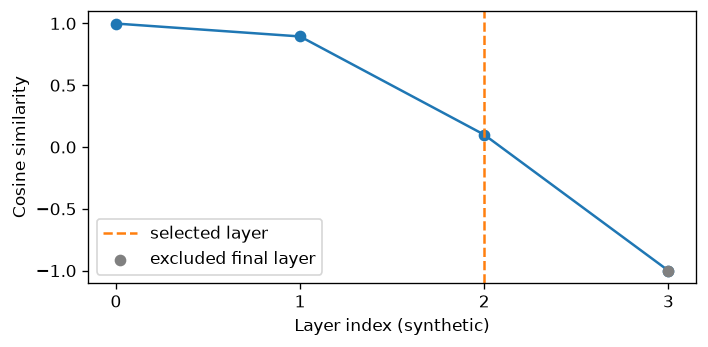

In [9]:
# ✅ 확인 셀
assert clean_mean.shape == conflict_mean.shape == (L,D)
assert np.argmin(cosines) == L-1, '자료 전체의 최소는 제외 대상인 마지막 층에 있습니다.'
assert ell == 2
np.testing.assert_allclose(v, [.9,-1,0,0], atol=1e-12)
print('✅ 평균 계산 → 적격 층 선택 → clean - conflict 방향 추출을 확인했습니다.')

plt.figure(figsize=(6,3))
plt.plot(range(L), cosines, 'o-')
plt.axvline(ell, ls='--', color='tab:orange', label='selected layer')
plt.scatter([L-1], [cosines[-1]], color='gray', label='excluded final layer', zorder=3)
plt.xlabel('Layer index (synthetic)'); plt.ylabel('Cosine similarity')
plt.xticks(range(L)); plt.legend(); plt.tight_layout(); plt.show()


### 문제 2-3 (서술형)
1. 왜 같은 토큰 위치 번호를 비교하지 않고 각 입력의 마지막 토큰을 비교하나요?
2. `conflict - clean`으로 방향을 정의하면 α 부호의 의미는 어떻게 달라지나요?
3. 이 배열에서 층 2가 선택됐다는 결과로 실제 Llama에서도 층 2가 가장 좋다고 말할 수 있나요?


**답:** 
1. 문맥이 추가되면 입력 길이와 패딩 위치가 달라지므로 같은 절대 위치는 다른 토큰 또는 패딩을 가리킬 수 있다. 각 입력의 마지막 실제 토큰을 비교해야 한다.
2. 벡터가 반대가 되어 양의 α는 문맥 방향, 음의 α는 파라미터 방향이 된다. v와 α를 둘 다 반대로 바꾸면 같은 개입이다.
3. 말할 수 없다. 이 자료는 선택 규칙을 확인하도록 만든 합성 배열이다. 실제 모델에서는 해당 모델의 실제 활성화로 다시 층을 선택해야 한다.


---
## Part 3. 가중치를 바꾸지 않고 활성화 수정하기

### 문제 3-1. 선택한 층·토큰에만 개입

$$h'=h+\alpha v$$

원 배열은 보존하고 복사본에서 **선택한 층의 각 입력 마지막 실제 토큰**만 수정하세요. 실제 논문은 MLP와 잔차 덧셈이 끝난 `resid_post`에 개입합니다. 아래 배열은 그 위치의 표현을 가정한 자료이며 실제 Transformer를 실행하지 않습니다.


In [10]:
def steer_states(states, mask, layer, direction, alpha):
    changed = states.copy()
    last = np.where(mask == 1, np.arange(mask.shape[1])[None,:], -1).max(axis=1)
    current = changed[layer, np.arange(mask.shape[0]), last, :]
    changed[layer, np.arange(mask.shape[0]), last, :] = current + alpha * direction  # 풀이 ⑨
    return changed

before = conflict_states.copy()
after = steer_states(conflict_states, conflict_mask, ell, v, alpha=1.0)


In [11]:
# ✅ 확인 셀
np.testing.assert_array_equal(conflict_states, before)
np.testing.assert_array_equal(steer_states(before, conflict_mask, ell, v, 0.0), before)
mask_changed = np.any(after != before, axis=-1)
expected = np.zeros((L,B,T), dtype=bool)
last = np.where(conflict_mask==1, np.arange(T)[None,:], -1).max(axis=1)
expected[ell,np.arange(B),last] = True
np.testing.assert_array_equal(mask_changed, expected)
np.testing.assert_allclose(last_token_states(after, conflict_mask)[ell].mean(axis=0), clean_mean[ell], atol=1e-12)
print('✅ 원본·다른 층·다른 토큰은 유지되고 지정한 활성화만 바뀝니다.')


✅ 원본·다른 층·다른 토큰은 유지되고 지정한 활성화만 바뀝니다.


### 문제 3-2. α에 따른 출력 변화 관찰

고정된 선형 분류기는 은닉 벡터를 `parametric / contextual / other` 세 점수로 변환합니다. 아래 가중치는 **α의 부호에 따른 변화를 보이도록 직접 정한 값**입니다. 학습된 언어 모델의 출력층이 아닙니다.

세 클래스에 대한 softmax 확률을 관찰합니다. 이것은 논문의 집계 출처 매칭 비율과 다릅니다. argmax 출력은 α가 바뀔 때 이산적으로 전환되므로 모든 출력이 연속적으로 변한다고 쓰면 안 됩니다.


 alpha | P(param) P(context) P(other) | prediction
 -1.50 |    0.022      0.932    0.046 | contextual
 -1.25 |    0.034      0.908    0.058 | contextual
 -1.00 |    0.053      0.875    0.072 | contextual
 -0.75 |    0.081      0.831    0.088 | contextual
 -0.50 |    0.122      0.774    0.105 | contextual
 -0.25 |    0.177      0.701    0.122 | contextual
 +0.00 |    0.249      0.614    0.137 | contextual
 +0.25 |    0.337      0.515    0.148 | contextual
 +0.50 |    0.435      0.413    0.152 | parametric
 +0.75 |    0.534      0.316    0.149 | parametric
 +1.00 |    0.629      0.231    0.140 | parametric
 +1.25 |    0.711      0.163    0.127 | parametric
 +1.50 |    0.778      0.111    0.111 | parametric


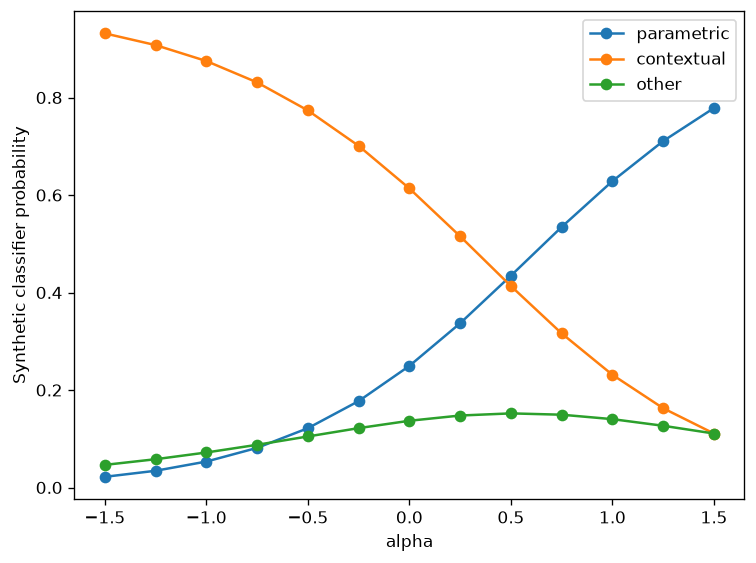

In [12]:
W = np.array([[1.,0.,0.], [0.,1.,0.], [0.,0.,.2], [0.,0.,.2]])
bias = np.array([0.,0.,-.5])
W.setflags(write=False); bias.setflags(write=False)
W_before = W.copy()
names = ['parametric', 'contextual', 'other']

def readout(h):
    logits = h @ W + bias
    exp = np.exp(logits - logits.max(axis=-1, keepdims=True))
    return exp / exp.sum(axis=-1, keepdims=True)

alphas = np.linspace(-1.5, 1.5, 13)
h = conflict_mean[ell]
probabilities = np.array([readout(h + a*v) for a in alphas])
print(' alpha | P(param) P(context) P(other) | prediction')
for a, p in zip(alphas, probabilities):
    print(f'{a:+6.2f} | {p[0]:8.3f} {p[1]:10.3f} {p[2]:8.3f} | {names[p.argmax()]}')

for i, name in enumerate(names):
    plt.plot(alphas, probabilities[:,i], 'o-', label=name)
plt.xlabel('alpha'); plt.ylabel('Synthetic classifier probability')
plt.legend(); plt.tight_layout(); plt.show()


In [13]:
# ✅ 확인 셀
np.testing.assert_array_equal(W, W_before)
np.testing.assert_allclose(probabilities.sum(axis=1), 1.0)
assert np.all(np.diff(probabilities[:,0]) > 0)
assert np.all(np.diff(probabilities[:,1]) < 0)
assert names[readout(h - v).argmax()] == 'contextual'
assert names[readout(h + v).argmax()] == 'parametric'
print('✅ 가중치는 그대로이며, 이 합성 분류기에서는 α의 부호에 따라 출처 선호가 바뀝니다.')


✅ 가중치는 그대로이며, 이 합성 분류기에서는 α의 부호에 따라 출처 선호가 바뀝니다.


### 문제 3-3. α는 검증 데이터에서 선택

방향 v는 앞의 방향 추정용 자료에서 이미 계산했습니다. 다음은 **별도의 검증·테스트 합성 표현**입니다. 검증에서 목표 출처 선택 비율이 가장 높은 α를 정하고, 그 α를 테스트에 그대로 적용합니다. 동률이면 절댓값이 가장 작은 α를 고릅니다.

아래에서는 파라미터 방향(양의 α)만 선택합니다. 테스트 정답을 보고 α를 바꾸면 테스트 누수입니다. 단순화를 위해 테스트에서는 한 번 선택한 출처의 비율만 출력합니다.


In [14]:
validation_h = np.array([[0.,1.,0.,0.], [.1,1.,0.,0.], [.2,1.,0.,0.], [.3,1.,0.,0.]])
test_h = np.array([[-.1,1.,0.,0.], [.05,1.,0.,0.], [.15,1.,0.,0.], [.25,1.,0.,0.]])
candidate_alphas = [.25, .5, .75, 1.0]

def source_rate(hidden, alpha, target_class=0):
    pred = readout(hidden + alpha*v).argmax(axis=1)
    return float((pred == target_class).mean())

def select_alpha(validation_hidden, candidates):
    rates = [source_rate(validation_hidden, a) for a in candidates]
    best = max(rates)
    tied = [a for a, rate in zip(candidates, rates) if rate == best]
    return min(tied, key=abs), rates

chosen_alpha, validation_rates = select_alpha(validation_h, candidate_alphas)  # 풀이 ⑩: 검증 자료만 전달
test_before = source_rate(test_h, 0.0)
test_after = source_rate(test_h, chosen_alpha)
print('validation:', list(zip(candidate_alphas, validation_rates)))
print('selected alpha:', chosen_alpha)
print(f'test parametric-source rate: {test_before:.2f} -> {test_after:.2f}')


validation: [(0.25, 0.0), (0.5, 0.75), (0.75, 1.0), (1.0, 1.0)]
selected alpha: 0.75
test parametric-source rate: 0.00 -> 1.00


In [15]:
# ✅ 확인 셀
assert chosen_alpha == .75
assert validation_rates == [0.0, .75, 1.0, 1.0]
assert test_before == 0.0 and test_after == 1.0
print('✅ α는 validation에서 고르고 test에는 고정해서 적용했습니다.')


✅ α는 validation에서 고르고 test에는 고정해서 적용했습니다.


### 문제 3-4 (서술형)
1. 테스트 출처 선택 비율이 0%에서 100%가 됐습니다. 이 결과를 논문의 LLM 성능 재현이라고 할 수 있나요?
2. 실제 사용자가 α의 부호를 정하려면 어떤 정보가 필요한가요? 잘못된 문서를 제공하면 어떤 문제가 생기나요?


**답:** 
1. 아니다. 중심값·선형 분류기·자료를 설명용으로 구성했다. 이 결과는 구현의 계산 흐름을 확인할 뿐 실제 LLM의 성능이나 일반화를 입증하지 않는다.
2. 어떤 출처를 우선해야 하는지에 대한 과제 규칙 또는 출처의 정확성·최신성·신뢰도 판단이 필요하다. 문맥 의존을 높이면 잘못된 문서의 답도 더 잘 선택할 수 있다. 이 방법 자체는 출처의 진위를 판별하지 않는다.


---
## Part 4. 출처 매칭 지표와 논문 수치 해석

### 문제 4-1. 네 가지 라벨과 분모

논문의 통제된 사실 충돌 평가는 `parametric-only`, `contextual-only`, `both`, `neither`를 구분합니다. **both와 neither도 전체 N에 포함**합니다.

아래는 논문과 같은 문자열 포함 기준을 작은 예시로 확인합니다. 소문자 변환·문장부호 제거·앞 관사 제거·공백 정규화를 적용합니다. 단어 내부 하이픈은 유지합니다. 별칭은 이 실습에서 생략합니다. 모든 응답은 짧으므로 토크나이저와 256토큰 구간 추출은 구현하지 않습니다. `split()`의 단어 수를 실제 모델 토큰 수로 간주하면 안 됩니다.


In [16]:
def normalize_answer(text):
    text = text.lower()
    # 단어 내부의 하이픈만 보존합니다.
    text = re.sub(r'(?<!\w)-|-(?!\w)', ' ', text)
    punctuation = string.punctuation.replace('-', '')
    text = text.translate(str.maketrans('', '', punctuation))
    text = ' '.join(text.split())
    return re.sub(r'^(a|an|the)\s+', '', text)

def source_label(output, parametric_answer, contextual_answer):
    s = normalize_answer(output)
    p = normalize_answer(parametric_answer)
    c = normalize_answer(contextual_answer)
    if not p or not c or p == c:
        raise ValueError('두 답은 정규화 뒤에도 서로 다른 비어 있지 않은 문자열이어야 합니다.')
    has_p, has_c = p in s, c in s
    if has_p and has_c:
        return 'both'
    if has_p:
        return 'parametric-only'
    if has_c:
        return 'contextual-only'
    return 'neither'

outputs = ['Paris.', 'Lyon.', 'It is Paris, not Lyon.', 'I do not know.', 'The answer is Paris.']
labels = [source_label(s, 'Paris', 'Lyon') for s in outputs]

def source_metrics(labels):
    n = len(labels)
    if n == 0:
        raise ValueError('평가 항목이 없습니다.')
    acc_par = labels.count('parametric-only') / n  # 풀이 ⑪: parametric-only 수 / 전체 n
    acc_ctx = labels.count('contextual-only') / n  # 풀이 ⑫: contextual-only 수 / 전체 n
    return acc_par, acc_ctx

acc_par, acc_ctx = source_metrics(labels)
print('labels:', labels)
print(f'Acc_par={acc_par:.1%}, Acc_ctx={acc_ctx:.1%}')


labels: ['parametric-only', 'contextual-only', 'both', 'neither', 'parametric-only']
Acc_par=40.0%, Acc_ctx=20.0%


In [17]:
# ✅ 확인 셀
assert labels == ['parametric-only','contextual-only','both','neither','parametric-only']
assert acc_par == .4 and acc_ctx == .2
assert acc_par + acc_ctx < 1
assert source_metrics(['both','neither']) == (0.0,0.0)
assert normalize_answer('The NEW-YORK!') == 'new-york'
print('✅ both/neither를 버리지 않고 전체 항목을 분모로 사용했습니다.')


✅ both/neither를 버리지 않고 전체 항목을 분모로 사용했습니다.


### 문제 4-2 (서술형)
`It is Paris, not Lyon.`은 의미상 Paris를 선택하지만 위 코드에서는 both입니다. 이 지표의 한계를 설명하세요. 또한 Acc_ctx가 높아졌다는 것과 현실 사실의 정확도가 높아졌다는 것은 왜 다른가요?


**답:** 
문자열 지표는 부정·정정·인용의 의미를 이해하지 못하고 두 답의 등장 여부만 확인한다. 따라서 두 답을 모순되게 섞은 문장과 한 답을 명확히 부정한 문장이 같은 both가 될 수 있다. Acc_ctx는 문맥 답만 포함한 비율이며 문맥 답이 실제로 참인지는 측정하지 않는다. 반사실 문맥이면 Acc_ctx 상승은 틀린 정보를 더 잘 따랐다는 뜻일 수 있다.


### 문제 4-3. 실제 논문 보고값 계산

아래 `table1`, `table6`, `table7`은 각각 원문 **표 1(NQ-Swap/Llama)**, **표 6(Llama의 데이터셋 간 전이)**, **표 7(Llama의 복잡 과제 결과)**에서 가져왔습니다. 합성 실습 결과가 아닙니다. 표 7은 평균값만 사용하며 원문의 ± 값은 생략했습니다.

백분율 점수 두 개의 차이는 `%`가 아니라 **퍼센트포인트(%p)**로 보고합니다. 파라미터·문맥 행은 다른 부호의 개입 조건이며 한 번의 실행에서 동시에 얻은 비율이 아닙니다.


In [18]:
table1 = {'parametric': (33.7,56.8), 'contextual': (49.4,55.5)}
table6 = {
    'MacNoise': {'parametric':(46.2,60.0), 'contextual':(27.0,34.1)},
    'ParaConflict': {'parametric':(15.8,83.9), 'contextual':(81.4,90.8)},
    'CounterFact': {'parametric':(35.7,38.9), 'contextual':(60.0,60.7)},
    'MemoTrap': {'parametric':(66.7,75.4), 'contextual':(30.0,53.3)},
}
table7 = {
    'RGB': (62.0,82.0), 'CRAG': (23.7,25.8),
    'LoCoMo': (8.5,13.2), 'LoCoMo-Plus': (32.7,36.7),
    'LongMemEval': (43.2,45.4), 'IFEval': (33.6,35.0), 'FollowBench': (14.5,14.9),
}

def gain_pp(before, after):
    return after - before  # 풀이 ⑬: 반올림은 출력할 때만 합니다.

for source, (before,after) in table1.items():
    print(f'NQ-Swap/{source}: {before:.1f} -> {after:.1f} | {gain_pp(before,after):+.1f}%p')
print('\n[논문 표 7]')
for task,(before,after) in table7.items():
    print(f'{task:14s} {before:5.1f} -> {after:5.1f} | {gain_pp(before,after):+4.1f}%p')


NQ-Swap/parametric: 33.7 -> 56.8 | +23.1%p
NQ-Swap/contextual: 49.4 -> 55.5 | +6.1%p

[논문 표 7]
RGB             62.0 ->  82.0 | +20.0%p
CRAG            23.7 ->  25.8 | +2.1%p
LoCoMo           8.5 ->  13.2 | +4.7%p
LoCoMo-Plus     32.7 ->  36.7 | +4.0%p
LongMemEval     43.2 ->  45.4 | +2.2%p
IFEval          33.6 ->  35.0 | +1.4%p
FollowBench     14.5 ->  14.9 | +0.4%p


In [19]:
# ✅ 확인 셀
assert round(gain_pp(*table1['parametric']),1) == 23.1
assert round(gain_pp(*table1['contextual']),1) == 6.1
assert round(gain_pp(*table6['CounterFact']['contextual']),1) == .7
assert round(gain_pp(*table7['CRAG']),1) == 2.1
assert round(gain_pp(*table7['LoCoMo-Plus']),1) == 4.0
print('✅ %p 차이를 계산했습니다. 부록 표 19의 일부 증가량 대신 본문 표 7 전후 값으로 계산합니다.')


✅ %p 차이를 계산했습니다. 부록 표 19의 일부 증가량 대신 본문 표 7 전후 값으로 계산합니다.


### 문제 4-4 (서술형)
1. NQ-Swap에서 Llama의 파라미터 선택과 문맥 선택은 각각 몇 %p 증가했나요?
2. 표 6만으로 모든 목표 데이터셋에서 큰 효과가 있다고 말할 수 있나요? 수치를 하나 이상 사용하세요.
3. 표 7의 RGB와 FollowBench는 각각 얼마나 개선됐나요? 이 둘을 같은 종류의 정확도로 직접 비교하면 왜 안 되나요?


**답:** 
1. 파라미터 선택 +23.1%p, 문맥 선택 +6.1%p다. 서로 다른 부호의 개입 결과다.
2. 아니다. CounterFact 문맥 선택은 60.0→60.7로 +0.7%p에 그친다. 전이 효과의 크기는 데이터셋에 따라 다르다.
3. RGB +20.0%p, FollowBench +0.4%p다. RGB는 제공된 반사실 근거의 답을 따르는지를 평가하고, FollowBench는 출력 제약 준수 등을 평가한다. 과제·평가기·난도가 달라 같은 의미의 정확도로 직접 비교할 수 없다. 표 7 전체 개선을 동일한 크기의 효과라고 해석해서도 안 된다.


---
## Part 5. 서술형 복습과 토론

수치·설정에 근거해 답하세요. 모호하게 “성능이 좋아진다”라고 쓰기보다 **어떤 입력에서 어떤 지표가 어떻게 바뀌는지** 설명하세요. 아래 답은 하나의 정답 문장을 요구하지 않으며 논리와 근거를 평가합니다.


### 문제 5-1. 개입 방향의 결정
실제 입력에서는 어느 출처가 정확한지 미리 알 수 없습니다. 이 방법만으로 일반적인 사실 정확도를 높일 수 있나요? 문서 기준 답변 과제와 일반 사실 질의응답을 구분해 설명하세요.


**답:** 
제공된 회사 규정 등 특정 문서에 따라 답하는 과제는 우선할 출처가 정해져 있으므로 문맥 의존을 높이는 개입이 유용할 수 있다. 그러나 일반 사실 질의응답에서 문서가 틀렸는지 기존 지식이 틀렸는지는 이 방법이 판별하지 않는다. 문맥을 더 잘 따르는 것만으로 사실 정확도 개선을 보장할 수 없으며, 출처 신뢰도·최신성 등으로 개입 방향을 정하는 별도 절차와 그 절차를 포함한 평가가 필요하다.


### 문제 5-2. 지식 충돌인가, 일반적인 문맥 의존도인가?
충돌·일치·무관 문맥을 사용한 통제 실험과 복잡 과제 전이는 두 해석에 어떤 근거를 제공하나요? 둘을 구분할 추가 실험을 하나 제안하세요.


**답:** 
충돌 문맥 대조 방향의 효과가 가장 컸다는 것은 충돌 조건이 중요하다는 근거다. 하지만 일치·무관 문맥 대조에도 효과가 있고 방향 간 코사인 유사도도 약 0.875–0.899로 높으며 규칙 준수 등에도 전이되므로, 충돌에만 특화됐다고 단정하기 어렵다. 같은 질문·비슷한 길이와 구조의 문맥에서 기존 지식과의 일치 여부만 달리하고, 같은 방향과 고정 α로 충돌 조건의 출처 선택 변화와 비충돌 조건의 문맥 활용 변화를 비교할 수 있다. 평가는 별도 테스트에서 수행한다.


### 문제 5-3. RAG와의 관계
RAG와 이 논문의 스티어링은 각각 어느 단계에서 무슨 역할을 하나요? RAG 성능 향상을 전부 지식 충돌 해결로 설명할 수 없는 이유도 쓰세요.


**답:** 
RAG는 외부 문서를 검색해 모델 입력으로 제공하는 절차다. 이 스티어링은 그 입력을 처리하는 모델의 특정 층·토큰 활성화를 수정해 지식원 의존에 개입한다. 함께 사용할 수 있다. RAG의 모든 항목에 기존 지식과의 명시적 충돌이 있는 것은 아니며, 점수 개선은 근거 위치 특정·정보 추출·추론 등의 변화로도 생길 수 있어 전부 충돌 해결이라고 설명할 수 없다.


### 문제 5-4. 성능 보존과 적용 범위
1. 충돌 없는 MacNoise 입력의 원래 답 정확도는 개입 없음 100.0, 파라미터 방향 80.8, 문맥 방향 86.7이었습니다(표 5). 이 결과가 항상 개입하는 정책에 주는 시사점은 무엇인가요?
2. API로 텍스트 입출력만 제공하는 모델에 이 방법을 그대로 적용할 수 있나요?


**답:** 
1. 충돌 없는 입력에서도 개입이 정확도를 낮출 수 있다. 따라서 항상 개입하는 정책의 비용을 따로 평가하고, 개입 여부·강도를 정하거나 불확실하면 α=0을 쓰는 절차를 검토해야 한다. 후자는 추가 설계 제안이지 논문이 해결한 결과는 아니다.
2. 그대로는 적용할 수 없다. 내부 잔차 활성화를 읽고 수정하는 화이트박스 접근이 필요하다. 텍스트 프롬프트 변경만으로 동일한 내부 개입을 수행할 수는 없다.


### 문제 5-5. 직접 확인한 사실과 확인하지 못한 주장
이 과제에서 직접 확인한 사실 두 가지와, 이 과제만으로는 확인할 수 없는 논문의 주장 두 가지를 구분해 쓰세요.


**답:** 
직접 확인: (1) 합성 배열에서 평균 벡터의 코사인 유사도로 적격 층을 고르고 clean−conflict 벡터를 계산했다. (2) 지정한 활성화만 수정하고 고정 선형 가중치를 유지하며 출력 확률을 바꿨다. 네 라벨의 분모 처리와 보고값 차이 계산도 확인했다.
확인하지 못함: (1) 실제 Llama·Qwen 등의 잔차 스트림에 일반화 가능한 지식 선택 방향이 존재한다는 주장. (2) 해당 방향이 실제 RAG·기억·규칙 준수 과제에 전이된다는 주장. 이들은 실제 모델 활성화·데이터·공식 평가기로 독립 검증해야 한다. 표의 수치를 읽은 것은 재현 실험이 아니다.
